# Small-library interpolation benchmark

Live analysis of the strongly triaxial TNT experiment: 32 launches, four force
evaluators, and nominal tolerances `1e-5`, `1e-7`, `1e-9`, `1e-11` (512 solves).
**Rerun all cells to refresh.** Missing results are pending, not successful zeros.
The benchmark continues independently; this notebook never launches integrations.

Both initializers use `(nE,nI2,nI3)=(2,4,2)`. Interpolation grids use
`(160,24,24)` nodes over `1e-5–200 kpc`. All orbits span 200 shared shell periods
with 50,000 saved samples. Linear/cubic interpolate force coefficients; Hermite
interpolates the potential with autodiff nodal derivatives.

In [134]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import numpy as np
import matplotlib.pyplot as plt

# Works from the repository root or this notebook's directory.
ROOT = next(p / "benchmarks/interpolation_library" for p in
            [Path.cwd(), *Path.cwd().parents]
            if (p / "benchmarks/interpolation_library/input/config.yaml").exists())
RUN_DIRS = [ROOT / "work/suite-20261111", ROOT / "work/suite-1e-5-20261111"]
METHODS = ["direct", "linear", "cubic", "hermite"]
LABELS = dict(direct="Direct", linear="Trilinear force", cubic="Cubic force",
              hermite="Hermite potential")
COLORS = dict(zip(METHODS, ["black", "tab:orange", "tab:blue", "tab:green"]))
TOLERANCES = [1e-11, 1e-9, 1e-7, 1e-5]
N_ORBITS = 32
ORBIT_INDEX = 0                # 0–15 boundary starts; 16–31 stationary starts
SELECTED_TOLERANCE = 1e-9
REFERENCE_TOLERANCE = 1e-11   # Working reference, not an exact trajectory
PLOT_STRIDE = 10
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True,
                     "grid.alpha": .2, "font.size": 10})

def table(headers, rows):
    values = [list(map(str, headers)), *[list(map(str, row)) for row in rows]]
    widths = [max(len(row[i]) for row in values) for i in range(len(headers))]
    for row in values:
        print("  ".join(value.ljust(width) for value, width in zip(row, widths)))

def load_records():
    result = {}
    for directory in RUN_DIRS:
        for path in sorted(directory.glob("orbit-*.json")):
            try:
                row = json.loads(path.read_text())
            except json.JSONDecodeError:
                print("Record being written or incomplete:", path.name)
                continue
            key = (row["index"], row["method"], row["tolerance"])
            if key in result:
                raise ValueError(f"Duplicate result: {key}")
            row["path"] = path
            result[key] = row
    return result

records = load_records()
print("Snapshot time:", datetime.now(ZoneInfo("Europe/Vienna")).isoformat(timespec="seconds"))
print(f"Snapshot: {len(records)} / {N_ORBITS * len(METHODS) * len(TOLERANCES)} results")

# Convert stored launch-scale energy errors to one reference kinetic scale per orbit.
launch_path = next((d / "launches.npz" for d in RUN_DIRS
                    if (d / "launches.npz").exists()), None)
energy_factors = {}
reference_mean_v2 = {}
if launch_path is not None:
    with np.load(launch_path, allow_pickle=False) as saved:
        launch_data = {key: saved[key] for key in saved.files}
    for index in range(N_ORBITS):
        row = records.get((index, "direct", REFERENCE_TOLERANCE))
        if not row or not row["successful"] or not row["path"].with_suffix(".npz").exists():
            continue
        with np.load(row["path"].with_suffix(".npz"), allow_pickle=False) as saved:
            mean_v2 = np.mean(np.sum(saved["velocities_kpc_Myr"]**2, axis=1))
        if not np.isfinite(mean_v2) or mean_v2 <= 0:
            raise ValueError(f"Invalid reference mean-square speed for orbit {index}")
        period = launch_data["periods"][index]
        q0, v0 = launch_data["positions"][index], launch_data["velocities"][index]
        old_speed = max(2*np.pi*np.linalg.norm(q0)/period, np.linalg.norm(v0))
        reference_mean_v2[index] = mean_v2
        energy_factors[index] = old_speed**2 / mean_v2
print(f"Reference energy scales available: {len(energy_factors)}/{N_ORBITS}")

Snapshot time: 2026-11-11T15:38:09+01:00
Snapshot: 512 / 512 results
Reference energy scales available: 32/32


## Completeness and failures

Only groups with 32 successful, saved trajectories are complete. A failure is
reported separately from pending results. The `1e-5` extension runs after the
original matrix; the two directories share the launch set and grid artifacts.

In [135]:
status = []
for tolerance in TOLERANCES:
    for method in METHODS:
        rows = [r for (_, m, t), r in records.items() if m == method and t == tolerance]
        success = sum(r["successful"] and r["path"].with_suffix(".npz").exists()
                      for r in rows)
        failed = sum(not r["successful"] for r in rows)
        status.append([f"{tolerance:.0e}", LABELS[method], success, failed,
                       N_ORBITS - len(rows), "complete" if success == N_ORBITS else "partial"])
table(["Tolerance", "Evaluator", "Saved OK", "Failed", "Pending", "Status"], status)
for row in records.values():
    if not row["successful"]:
        message = row.get("error", str(row.get("diagnostics")))
        reason = ("Grid domain/non-finite-query guard"
                  if "outside its declared radius range" in message else message[:160])
        print("FAILURE:", row["path"].name, reason)

Tolerance  Evaluator          Saved OK  Failed  Pending  Status  
1e-11      Direct             32        0       0        complete
1e-11      Trilinear force    24        8       0        partial 
1e-11      Cubic force        24        8       0        partial 
1e-11      Hermite potential  24        8       0        partial 
1e-09      Direct             32        0       0        complete
1e-09      Trilinear force    24        8       0        partial 
1e-09      Cubic force        24        8       0        partial 
1e-09      Hermite potential  24        8       0        partial 
1e-07      Direct             32        0       0        complete
1e-07      Trilinear force    24        8       0        partial 
1e-07      Cubic force        24        8       0        partial 
1e-07      Hermite potential  24        8       0        partial 
1e-05      Direct             32        0       0        complete
1e-05      Trilinear force    8         24      0        partial 
1e-05     

## Setup and integration costs

Construction times are measured once per method, separately from compilation.
The suite reuses pilot tables; copied setup records are counted once. Integration
includes the solver's direct-energy diagnostics but excludes the subsequent
energy-history export and file I/O. These are single executions, not repeated
warm timing estimates; machine state and execution order can affect comparisons.
The timing plot uses a single common successful orbit subset across all
currently comparable evaluator/tolerance groups; its size and IDs are printed.
This is a subset timing, not a complete-library result. Tolerances with no
successful result for one evaluator are omitted. The table retains full-library
completion status and partial totals. The subset may change as new data arrive.


Evaluator          Grid compile (s)  Construct (s)  Table MiB
Trilinear force    0.201             0.495          2.109    
Cubic force        0.453             0.844          2.109    
Hermite potential  1.341             13.632         5.625    
Matched timing subset: 7/32 orbits
Orbit IDs: [0, 1, 2, 3, 4, 5, 7]


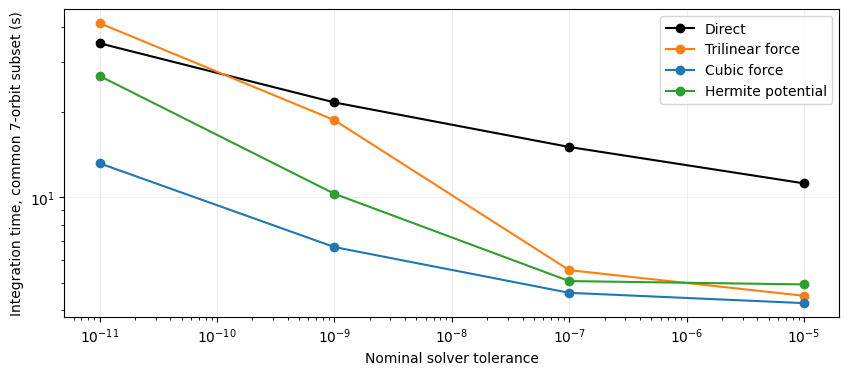

Evaluator          Tolerance  Successful  Full library (s)  Partial sum (s)
Direct             1e-11      32          292.05            292.05         
Direct             1e-09      32          163.17            163.17         
Direct             1e-07      32          115.14            115.14         
Direct             1e-05      32          104.19            104.19         
Trilinear force    1e-11      24          pending           296.04         
Trilinear force    1e-09      24          pending           142.46         
Trilinear force    1e-07      24          pending           32.08          
Trilinear force    1e-05      8           pending           5.21           
Cubic force        1e-11      24          pending           68.35          
Cubic force        1e-09      24          pending           36.03          
Cubic force        1e-07      24          pending           21.47          
Cubic force        1e-05      9           pending           5.92           
Hermite pote

In [136]:
construction = {}
for directory in RUN_DIRS:
    for method in METHODS[1:]:
        path = directory / f"grid-{method}.json"
        if path.exists():
            try:
                row = json.loads(path.read_text())
            except json.JSONDecodeError:
                print("Record being written or incomplete:", path.name)
                continue
            if method in construction and construction[method] != row:
                raise ValueError(f"Conflicting grid setup: {method}")
            construction[method] = row
table(["Evaluator", "Grid compile (s)", "Construct (s)", "Table MiB"],
      [[LABELS[m], f"{r['compilation_seconds']:.3f}",
        f"{r['construction_seconds']:.3f}", f"{r['bytes']/2**20:.3f}"]
       for m, r in construction.items()])

runtime_rows = []
# One common successful subset across all currently comparable groups.
comparable_tolerances = [t for t in TOLERANCES if all(
    any(i_method == m and i_tol == t and r["successful"]
        for (_, i_method, i_tol), r in records.items()) for m in METHODS)]
common_indices = set(range(N_ORBITS))
for t in comparable_tolerances:
    for m in METHODS:
        common_indices &= {i for (i, method, tol), r in records.items()
                           if method == m and tol == t and r["successful"]}
if not comparable_tolerances:
    common_indices = set()
print(f"Matched timing subset: {len(common_indices)}/{N_ORBITS} orbits")
print("Orbit IDs:", sorted(common_indices))
fig, ax = plt.subplots()
for method in METHODS:
    totals = []
    for tolerance in TOLERANCES:
        rows = [r for (_, m, t), r in records.items() if m == method and t == tolerance]
        ok = [r for r in rows if r["successful"]]
        complete = len(ok) == N_ORBITS
        elapsed = sum(r.get("integration_seconds", 0) for r in ok)
        runtime_rows.append([LABELS[method], f"{tolerance:.0e}", len(ok),
                             f"{elapsed:.2f}" if complete else "pending",
                             f"{elapsed:.2f}"])
        matched = [r for r in ok if r["index"] in common_indices]
        totals.append(sum(r["integration_seconds"] for r in matched)
                      if tolerance in comparable_tolerances and common_indices
                      else np.nan)
    ax.plot(TOLERANCES, totals, "o-", color=COLORS[method], label=LABELS[method])
ax.set(xscale="log", yscale="log", xlabel="Nominal solver tolerance",
       ylabel=f"Integration time, common {len(common_indices)}-orbit subset (s)")
ax.legend()
plt.show()
table(["Evaluator", "Tolerance", "Successful", "Full library (s)", "Partial sum (s)"],
      runtime_rows)

## Physical-energy drift and adaptive work

Energy drift is `(E(t) − E(0)) / ⟨|v|²⟩ref`. The denominator is the mean-square
speed over all 50,000 saved samples of the **same orbit's direct-force `1e-11`
reference trajectory**, shared across all evaluators and tolerances. It is not
relative to initial energy and does not depend on the potential's additive zero.
Nominal tolerance remains a normalized state tolerance, not an energy bound.

Stored errors use the integrator's launch scale; the notebook converts them to
the reference kinetic scale without changing the saved data or integrator.
Maximum errors include all saved samples and the exact endpoint. Energy points
with unavailable reference scales are omitted; adaptive-step points do not need
a reference. Partial groups are not representative full-library comparisons.
Position and velocity trajectory-error plots retain their original launch scales.

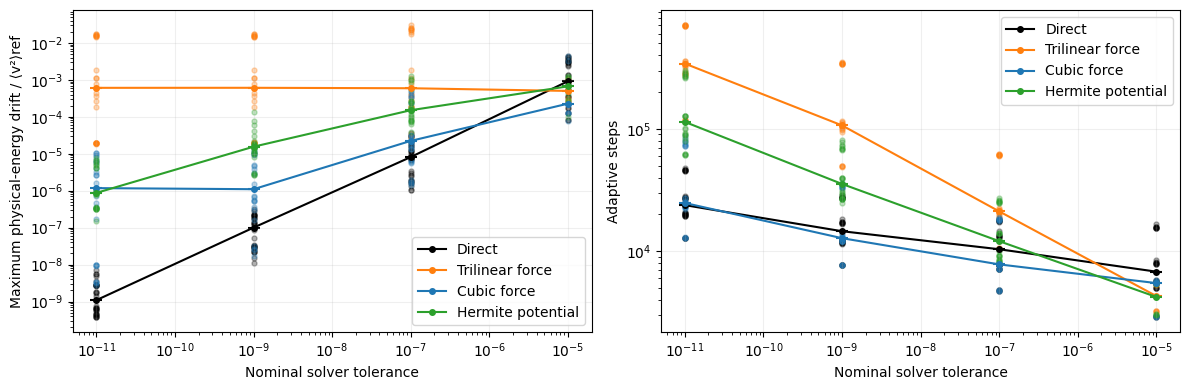

In [137]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method in METHODS:
    median_tolerances, median_errors = [], []
    step_tolerances, median_steps = [], []
    for tolerance in TOLERANCES:
        rows = [r for (_, m, t), r in records.items()
                if m == method and t == tolerance and r["successful"]]
        if not rows:
            continue
        errors = [r["diagnostics"]["max_energy_error"] * energy_factors[r["index"]]
                  for r in rows if r["index"] in energy_factors]
        if errors:
            median_tolerances.append(tolerance)
            median_errors.append(np.median(errors))
        steps = [r["diagnostics"]["num_steps"] for r in rows]
        step_tolerances.append(tolerance)
        median_steps.append(np.median(steps))
        for ax, values in zip(axes, [errors, steps]):
            if not values:
                continue
            ax.scatter([tolerance]*len(values), values, s=13, alpha=.3,
                       color=COLORS[method])
            ax.scatter(tolerance, np.median(values), s=65, marker="_",
                       color=COLORS[method])
    axes[0].plot(median_tolerances, median_errors, "o-",
                 color=COLORS[method], label=LABELS[method], markersize=4)
    axes[1].plot(step_tolerances, median_steps, "o-",
                 color=COLORS[method], label=LABELS[method], markersize=4)
for ax, ylabel in zip(axes, ["Maximum physical-energy drift / ⟨v²⟩ref", "Adaptive steps"]):
    ax.set(xscale="log", yscale="log", xlabel="Nominal solver tolerance", ylabel=ylabel)
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## Selected orbit: trajectories and energy histories

Change `ORBIT_INDEX` and `SELECTED_TOLERANCE` above, then rerun. Comparisons use
the same launch, shell clock, random sampling key, and output times. The
`1e-11` direct trajectory is a numerical reference; its own convergence error
is not zero. Long-time trajectory separation for sensitive orbits is not by
itself an observable-error estimate or proof of chaos.

Orbit 0: XZGridFromBoundary; clock=0.180335 Myr; tolerance=1e-09
Available: direct, linear, cubic, hermite


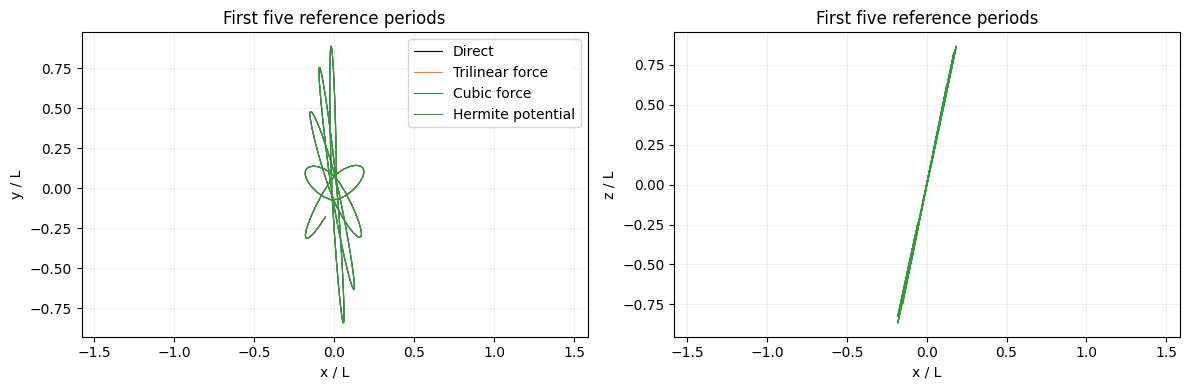

In [138]:
def read_trajectory(index, method, tolerance):
    row = records.get((index, method, tolerance))
    if not row or not row["successful"]:
        return None
    path = row["path"].with_suffix(".npz")
    if not path.exists():
        return None
    with np.load(path, allow_pickle=False) as saved:
        return {key: saved[key] for key in saved.files}

launch_file = next((d / "launches.npz" for d in RUN_DIRS
                    if (d / "launches.npz").exists()), None)
if launch_file is None:
    raise FileNotFoundError("No launch file yet; rerun after setup completes")
with np.load(launch_file, allow_pickle=False) as saved:
    launches = {key: saved[key] for key in saved.files}
assert 0 <= ORBIT_INDEX < len(launches["periods"])
period = launches["periods"][ORBIT_INDEX]
q0, v0 = launches["positions"][ORBIT_INDEX], launches["velocities"][ORBIT_INDEX]
length = max(np.linalg.norm(q0), np.linalg.norm(v0) * period/(2*np.pi))
speed = 2*np.pi*length/period
selected = {method: data for method in METHODS
            if (data := read_trajectory(ORBIT_INDEX, method, SELECTED_TOLERANCE)) is not None}
reference = read_trajectory(ORBIT_INDEX, "direct", REFERENCE_TOLERANCE)
print(f"Orbit {ORBIT_INDEX}: {launches['sampler'][ORBIT_INDEX]}; "
      f"clock={period:.6g} Myr; tolerance={SELECTED_TOLERANCE:.0e}")
print("Available:", ", ".join(selected) or "none yet")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method, data in selected.items():
    subset = np.flatnonzero(data["times_Myr"] / period <= 5)[::PLOT_STRIDE]
    q = data["positions_kpc"][subset] / length
    for ax, y in zip(axes, [1, 2]):
        ax.plot(q[:, 0], q[:, y], lw=.8, color=COLORS[method], label=LABELS[method])
for ax, y in zip(axes, ["y", "z"]):
    ax.set(xlabel="x / L", ylabel=f"{y} / L", title="First five reference periods")
    ax.set_aspect("equal", adjustable="datalim")
if selected:
    axes[0].legend()
plt.tight_layout()
plt.show()

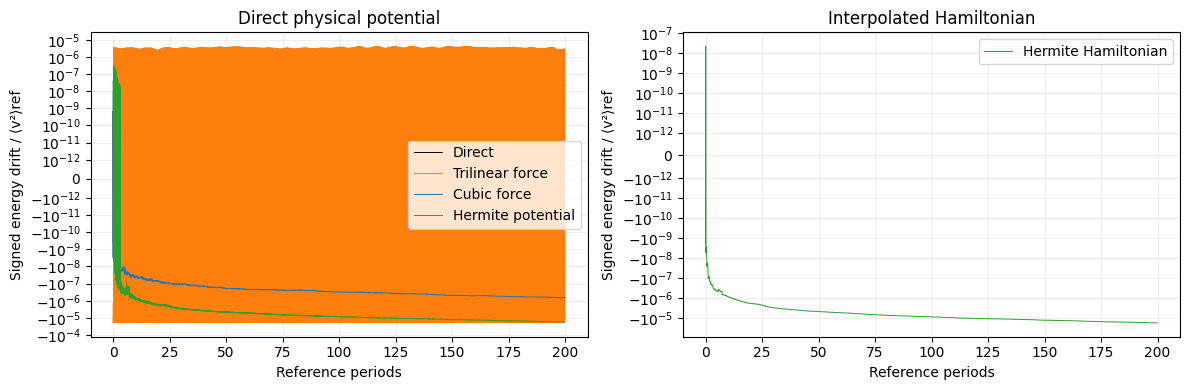

In [139]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
energy_factor = energy_factors.get(ORBIT_INDEX)
if energy_factor is None:
    print("Reference kinetic scale pending; energy histories omitted.")
for method, data in selected.items():
    if energy_factor is None:
        continue
    t = data["times_Myr"][::PLOT_STRIDE] / period
    axes[0].plot(t, data["physical_energy_drift"][::PLOT_STRIDE] * energy_factor, lw=.7,
                 color=COLORS[method], label=LABELS[method])
    if "hermite_energy_drift" in data:
        axes[1].plot(t, data["hermite_energy_drift"][::PLOT_STRIDE] * energy_factor, lw=.7,
                     color=COLORS[method], label="Hermite Hamiltonian")
for ax, title in zip(axes, ["Direct physical potential", "Interpolated Hamiltonian"]):
    ax.set(xlabel="Reference periods", ylabel="Signed energy drift / ⟨v²⟩ref", title=title,
           yscale="symlog")
    ax.set_yscale("symlog", linthresh=1e-12)
    if ax.lines:
        ax.legend()
plt.tight_layout()
plt.show()
# Histories contain saved samples; exact-endpoint errors are in JSON diagnostics.

## Selected orbit: intrinsic (x, y, vz) density marginals

Use only the second half of each trajectory (last 25,000 saved samples),
without plotting subsampling. The reference bounds use that same second half. Histogram edges come from
this orbit's direct `1e-11` reference, padded by 30% of each coordinate span at
each end, and are shared by all evaluators. Each 3D count is divided by the
**second-half sample count and bin volume**. Thus each displayed marginal
integrates to the fraction inside the joint 3D bounds, not automatically one.
Samples outside any of the three bounds are reported in the table.

Rows compare the reference and the selected tolerance for each available force
evaluator; columns show `(x,y)`, `(x,vz)`, and `(y,vz)`. Each column shares one
logarithmic color scale across rows. Blank bins have zero counts; no smoothing,
PSF, spatial symmetry operation, or fitted orbit weight is applied. This is a
short-axis projection in intrinsic coordinates, not the configured observer view.


Orbit 0: shared (20, 20, 30) histogram, second half only
Coordinate  Lower bound  Upper bound
x (kpc)     -0.00383899  0.00382692 
y (kpc)     -0.0158231   0.0158155  
vz (km/s)   -599.614     600.478    
Evaluator                  Outside joint (x,y,vz) bounds  Marginal integral
Direct reference (1e-11)   0.0000%                        1.000000         
Direct (1e-09)             0.0000%                        1.000000         
Trilinear force (1e-09)    0.0000%                        1.000000         
Cubic force (1e-09)        0.0000%                        1.000000         
Hermite potential (1e-09)  0.0000%                        1.000000         


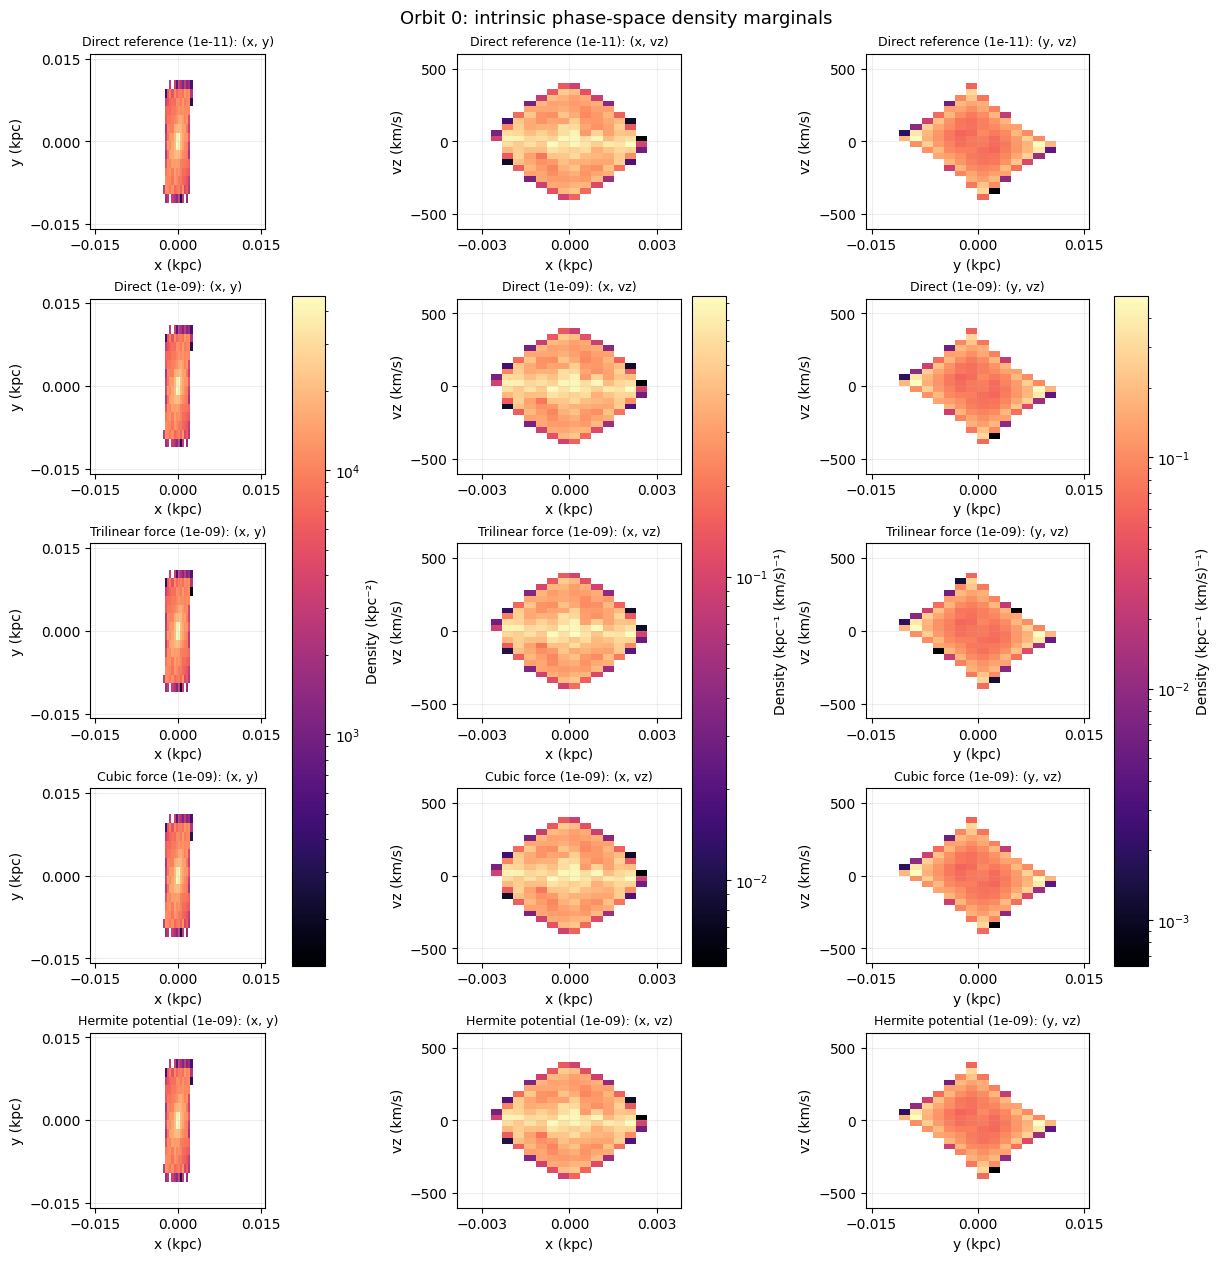

In [142]:
from matplotlib.colors import LogNorm
from matplotlib.ticker import MaxNLocator

DENSITY_BINS = (20, 20, 30)
DENSITY_PADDING = 0.30  # Add 30% of the reference span at EACH end.
KPC_PER_MYR_TO_KMS = 3.085677581491367e16 / (365.25 * 86400 * 1e6)


def phase_samples(data):
    start = len(data["times_Myr"]) // 2
    return np.column_stack([data["positions_kpc"][start:, :2],
                            data["velocities_kpc_Myr"][start:, 2] * KPC_PER_MYR_TO_KMS])


def orbit_density(samples, edges):
    # Never normalize to the number of samples that happen to fall inside.
    counts, _ = np.histogramdd(samples, bins=edges, density=False)
    widths = [np.diff(edge) for edge in edges]
    volume = widths[0][:, None, None] * widths[1][None, :, None] * widths[2][None, None, :]
    density = counts / (len(samples) * volume)
    marginals = [np.sum(density * widths[2][None, None, :], axis=2),
                 np.sum(density * widths[1][None, :, None], axis=1),
                 np.sum(density * widths[0][:, None, None], axis=0)]
    inside = counts.sum() / len(samples)
    areas = [widths[0][:, None] * widths[1][None, :],
             widths[0][:, None] * widths[2][None, :],
             widths[1][:, None] * widths[2][None, :]]
    for marginal, area in zip(marginals, areas):
        np.testing.assert_allclose(np.sum(marginal * area), inside, atol=1e-12)
    return marginals, 1 - inside


if reference is None:
    print("Direct 1e-11 reference pending; density plots omitted.")
else:
    reference_samples = phase_samples(reference)
    low, high = reference_samples.min(axis=0), reference_samples.max(axis=0)
    # Handle a degenerate coordinate without zero-width bins.
    span = np.maximum(high - low, np.maximum(np.maximum(abs(low), abs(high)), 1.) * 1e-12)
    edges = [np.linspace(lo - DENSITY_PADDING * width,
                         hi + DENSITY_PADDING * width, bins + 1)
             for lo, hi, width, bins in zip(low, high, span, DENSITY_BINS)]
    entries = [(f"Direct reference ({REFERENCE_TOLERANCE:.0e})", reference)]
    entries += [(f"{LABELS[method]} ({SELECTED_TOLERANCE:.0e})", data)
                for method, data in selected.items()]
    density_rows = [(label, *orbit_density(phase_samples(data), edges))
                    for label, data in entries]
    print(f"Orbit {ORBIT_INDEX}: shared {DENSITY_BINS} histogram, second half only")
    table(["Coordinate", "Lower bound", "Upper bound"],
          [[name, f"{edge[0]:.6g}", f"{edge[-1]:.6g}"]
           for name, edge in zip(["x (kpc)", "y (kpc)", "vz (km/s)"], edges)])
    table(["Evaluator", "Outside joint (x,y,vz) bounds", "Marginal integral"],
          [[label, f"{outside:.4%}", f"{1-outside:.6f}"]
           for label, _, outside in density_rows])

    fig, axes = plt.subplots(len(density_rows), 3,
                             figsize=(12, 2.5 * len(density_rows)),
                             squeeze=False, layout="constrained")
    pairs = [(0, 1), (0, 2), (1, 2)]
    axis_labels = ["x (kpc)", "y (kpc)", "vz (km/s)"]
    density_units = ["kpc⁻²", "kpc⁻¹ (km/s)⁻¹", "kpc⁻¹ (km/s)⁻¹"]
    for column, (a, b) in enumerate(pairs):
        positive = np.concatenate([marginals[column][marginals[column] > 0]
                                   for _, marginals, _ in density_rows])
        norm = LogNorm(vmin=positive.min(), vmax=max(positive.max(), positive.min()*1.01))
        for row, (label, marginals, _) in enumerate(density_rows):
            ax = axes[row, column]
            image = ax.pcolormesh(edges[a], edges[b],
                                 np.ma.masked_less_equal(marginals[column].T, 0),
                                 norm=norm, cmap="magma", shading="flat", rasterized=True)
            ax.set(xlabel=axis_labels[a], ylabel=axis_labels[b])
            ax.set_title(f"{label}: ({['x','y','vz'][a]}, {['x','y','vz'][b]})", fontsize=9)
            ax.xaxis.set_major_locator(MaxNLocator(3))
            ax.yaxis.set_major_locator(MaxNLocator(3))
            if column == 0:
                extent = max(abs(edges[0]).max(), abs(edges[1]).max())
                ax.set(xlim=(-extent, extent), ylim=(-extent, extent))
                ax.set_aspect("equal", adjustable="box")
        fig.colorbar(image, ax=axes[:, column].tolist(), label=f"Density ({density_units[column]})",
                     shrink=.7)
    fig.suptitle(f"Orbit {ORBIT_INDEX}: intrinsic phase-space density marginals", fontsize=13)
    plt.show()

## Reading the results

- Compare complete libraries or identical matched orbit subsets; do not rank
  partial totals against complete totals.
- Tightening tolerance isolates solver sensitivity, but does not remove force
  interpolation error. Compare direct tolerances as well as interpolators.
- Hermite can conserve its approximate Hamiltonian while differing from the
  physical one. Both histories matter; conservation alone is not force accuracy.
- Grid setup is paid per physical model. Current integration sums exclude it;
  compilation reuse and production-library throughput need separate treatment.
- Next: library-wide trajectory-error summaries, retained-distribution comparisons,
  and repeated/interleaved timing controls once the matrix is complete.

## Histogram of percentage errors in the 3D density

Using only the second half of each trajectory, for the selected orbit and
tolerance compare every occupied reference bin using
`100 × (ρ − ρref) / ρref`. The shared 3D edges and second-half-sample normalization are
the same as above. Errors are **signed** and weighted by reference probability per bin, equivalent
to normalized reference-density weighting on this equal-volume grid. Summary
percentiles use the same weights.

Zero-reference bins have undefined relative error: exclude them from the
histogram and report the probability assigned to those bins separately. The
out-of-bounds probability is also reported. The linear x-axis spans −100% to +100%, with 200 error bins. Larger positive
errors are outside the view; visible weights are not renormalized. The table
retains full-range statistics.


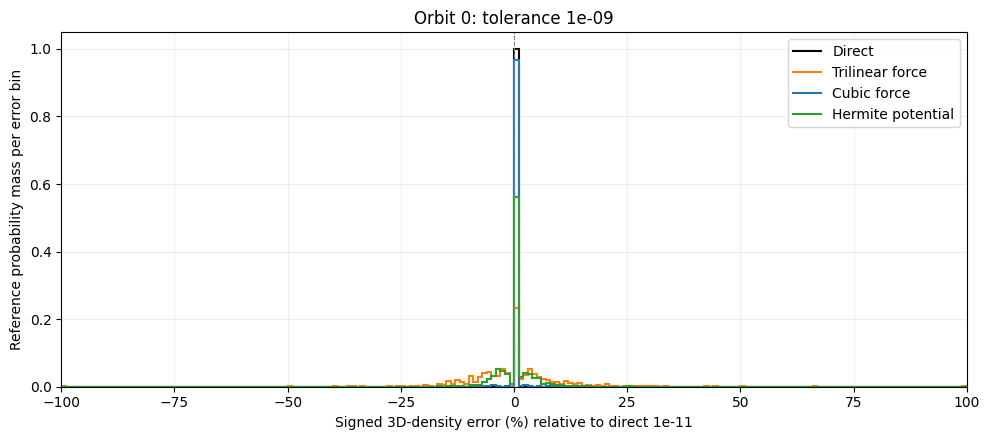

Evaluator          Reference bins  Weighted median |error|  Weighted 95th |error|  Reference mass at zero error  Mass in reference-empty bins  Mass outside bounds
Direct             1232            0.00%                    0.00%                  99.92%                        0.0000%                       0.0000%            
Trilinear force    1232            4.44%                    20.00%                 21.78%                        0.0800%                       0.0000%            
Cubic force        1232            0.00%                    0.00%                  96.10%                        0.0000%                       0.0000%            
Hermite potential  1232            0.00%                    7.69%                  56.10%                        0.0120%                       0.0000%            


In [143]:
if reference is None:
    print("Direct reference pending; 3D-density percentage errors omitted.")
else:
    reference_counts, _ = np.histogramdd(phase_samples(reference), bins=edges)
    reference_probability = reference_counts / len(phase_samples(reference))
    occupied = reference_probability > 0
    reference_weights = reference_probability[occupied]

    def weighted_percentile(values, weights, fraction):
        order = np.argsort(values)
        cumulative = np.cumsum(weights[order])
        index = np.searchsorted(cumulative, fraction * cumulative[-1], side="left")
        return values[order[min(index, len(order) - 1)]]


    percentage_errors = {}
    error_rows = []
    for method, data in selected.items():
        counts, _ = np.histogramdd(phase_samples(data), bins=edges)
        probability = counts / len(phase_samples(data))
        # Bin volumes cancel in the relative density error on shared edges.
        errors = 100 * (probability[occupied] - reference_probability[occupied]) / reference_probability[occupied]
        percentage_errors[method] = errors
        empty_reference_mass = probability[~occupied].sum()
        outside_mass = 1 - probability.sum()
        error_rows.append([LABELS[method], len(errors), f"{weighted_percentile(abs(errors), reference_weights, .5):.2f}%",
                           f"{weighted_percentile(abs(errors), reference_weights, .95):.2f}%",
                           f"{reference_weights[errors == 0].sum() / reference_weights.sum():.2%}",
                           f"{empty_reference_mass:.4%}", f"{outside_mass:.4%}"])
    if percentage_errors:
        error_edges = np.linspace(-100., 100., 201)
        fig, ax = plt.subplots(figsize=(10, 4.5))
        for method, errors in percentage_errors.items():
            histogram, _ = np.histogram(errors, bins=error_edges, weights=reference_weights)
            visible_mass = reference_weights[(errors >= -100) & (errors <= 100)].sum()
            np.testing.assert_allclose(histogram.sum(), visible_mass, atol=1e-12)
            ax.stairs(histogram, error_edges, color=COLORS[method],
                      label=LABELS[method], linewidth=1.5)
        ax.axvline(0, color="gray", linewidth=.8, linestyle="--")
        ax.set_xscale("linear")
        ax.set_xlim(-100., 100.)
        ax.set(xlabel="Signed 3D-density error (%) relative to direct 1e-11",
               ylabel="Reference probability mass per error bin",
               title=f"Orbit {ORBIT_INDEX}: tolerance {SELECTED_TOLERANCE:.0e}")
        ax.legend()
        plt.tight_layout()
        plt.show()
    table(["Evaluator", "Reference bins", "Weighted median |error|", "Weighted 95th |error|",
           "Reference mass at zero error", "Mass in reference-empty bins", "Mass outside bounds"], error_rows)
